# ДЗ 3 — улучшенная линейная регрессия

Предсказываем `price` и сохраняем **submission_improved.csv**. Основной алгоритм — `LinearRegression`; деревья и бустинг не используются. Исходная версия решения остаётся в `homework_03.ipynb` и `submission.csv`.

**Что изменено:** добавлены взаимодействия категорий (технология здания с площадью/комнатами, метро, лифтом и балконом); при обучении логарифма цены использованы умеренные веса объектов. Они помогают уменьшить дисбаланс между ошибкой в логарифмах и MAE в исходных единицах.

Модель имеет вид $\log\widehat{price}=b+\sum_jw_j\phi_j(x)$. Это линейная регрессия по коэффициентам на преобразованной цели; прогноз исходной цены вычисляется через exp.

Для запуска положите три исходных CSV в `data/` рядом с ноутбуком или в текущую папку. Выполните ячейки сверху вниз. Ноутбук самодостаточен: модуль `linear_improved.py` для него не обязателен.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
from pathlib import Path
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import (OneHotEncoder, StandardScaler,
                                   MinMaxScaler, PolynomialFeatures)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
SEED = 42
pd.set_option('display.max_columns', 30)
DATA_DIR = Path('data') if Path('data/train.csv').exists() else Path('.')
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
sample = pd.read_csv(DATA_DIR / 'sample_submission.csv')
assert 'price' in train and 'price' not in test
assert train.id.is_unique and test.id.is_unique
assert not set(train.id).intersection(test.id)
assert list(test.columns) == list(train.drop(columns='price').columns)
assert list(sample.columns) == ['id', 'price']
assert len(sample) == len(test) and set(sample.id) == set(test.id)
assert train.price.notna().all() and train.price.gt(0).all()
print('Train:', train.shape, 'Test:', test.shape)
display(train.head())

Train: (100000, 25) Test: (100000, 24)


,id,date,street_id,build_tech,floor,area,rooms,balcon,metro_dist,g_lift,n_photos,kw1,kw2,kw3,kw4,kw5,kw6,kw7,kw8,kw9,kw10,kw11,kw12,kw13,price
0,0,2011-1,560,NaN,2,59,3,0,30.0,1.0,5,0,1,0,0,0,0,0,0,0,0,0,0,0,4510000
1,1,2011-1,667,NaN,10,50,2,1,25.0,NaN,1,0,1,0,0,0,0,0,0,0,0,0,0,0,13231000
2,2,2011-1,90,0.0,1,48,2,0,25.0,0.0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,2008000
3,3,2011-1,94,1.0,3,62,3,1,30.0,NaN,3,0,1,0,0,0,0,0,0,0,0,0,0,0,12680000
4,4,2011-1,232,0.0,3,60,3,0,25.0,NaN,3,0,1,0,0,0,0,0,0,0,0,0,0,0,3335000


## 1. Протокол сравнения

Даты разбираются как календарные, а не как строки. В датасете train и test имеют частично перекрывающиеся календарные периоды; внутри train используем только обучение на прошлом и проверку на будущем.

Сравниваем исходную модель и новую на двух разбиениях:
- обучение до октября 2011, проверка октябрь–декабрь 2011;
- обучение до октября 2012, проверка октябрь–ноябрь 2012.

Выбираем параметры по среднему MAE этих двух разбиений с одинаковым весом для каждого периода. Декабрь 2012 проверяем после выбора, но он **уже оценивался в предыдущем решении**, поэтому это повторная диагностика, не независимый holdout. Первое временное разбиение тоже нельзя считать полностью нетронутым: его строки ранее использовались при обучении исходной модели. Выбор после нескольких экспериментов создаёт оптимизм локальной оценки.

Public-балл соревнования не используется для выбора параметров: пока был загружен только исходный submission. Улучшение локального MAE не гарантирует улучшение public/private.

In [2]:
dates = pd.to_datetime(train.date, format='%Y-%m')
X = train.drop(columns='price')
y = train.price
X_fit = X.loc[dates < '2012-10-01']
folds = [('2011 Q4', '2011-10-01', '2012-01-01'),
         ('2012 Oct–Nov', '2012-10-01', '2012-12-01')]
for name, start, end in folds:
    fit = dates < start
    valid = (dates >= start) & (dates < end)
    assert dates[fit].max() < dates[valid].min()
    print(name, 'train:', fit.sum(), 'validation:', valid.sum())

2011 Q4 train: 50056 validation: 16789
2012 Oct–Nov train: 83295 validation: 11116


## 2. Исходная модель для честного сравнения

Повторяем в точности конфигурацию предыдущего ноутбука: One-Hot категорий и их сочетаний, небольшая полиномиальная ветка, кусочно-линейный временной тренд, обычная линейная регрессия логарифма цены. Ниже приведены определения из первой версии, чтобы сравнение можно было повторить без внешнего Python-модуля.

In [3]:
class FeatureBuilder(BaseEstimator, TransformerMixin):
    def __init__(self, trend='linear'):
        self.trend = trend

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        out = X.drop(columns=['id', 'price'], errors='ignore').copy()
        d = pd.to_datetime(out.pop('date'), format='%Y-%m')
        t = (d.dt.year - 2011) * 12 + d.dt.month - 1
        out['time'] = t.astype(float)
        if self.trend == 'sqrt':
            out['time'] = np.sqrt(t + 1)
        elif self.trend == 'log':
            out['time'] = np.log1p(t)
        elif self.trend == 'piecewise':
            out['time_after_year'] = np.maximum(t - 11, 0)
        out['log_area'] = np.log(out['area'])
        out['area_per_room'] = out['area'] / out['rooms']
        out['first_floor'] = (out['floor'] == 1).astype(int)
        out['rooms_area'] = out.rooms.astype(str) + '_' + out.area.astype(str)
        tech = out.build_tech.fillna(-1).astype(str)
        out['floor_tech'] = out.floor.astype(str) + '_' + tech
        out['rooms_tech'] = out.rooms.astype(str) + '_' + tech
        return out

class FrequencyEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        values = np.asarray(X)
        self.maps_ = [pd.Series(values[:, i]).value_counts(normalize=True)
                      for i in range(values.shape[1])]
        return self

    def transform(self, X):
        values = np.asarray(X)
        return np.column_stack([
            pd.Series(values[:, i]).map(mapping).fillna(0).to_numpy()
            for i, mapping in enumerate(self.maps_)
        ])

# Небольшая проверка поведения на неизвестной категории.
enc_demo = FrequencyEncoder().fit(np.array([['A'], ['A'], ['B']]))
assert np.allclose(enc_demo.transform(np.array([['A'], ['new']])).ravel(), [2/3, 0])

def make_model(target='raw', encoding='onehot', scaler='standard',
               imputation='most_frequent', expanded=False, joint=False,
               poly=False, trend='linear', estimator='ols', alpha=1.0):
    cat_cols = ['street_id', 'build_tech', 'g_lift']
    if expanded:
        cat_cols += ['floor', 'rooms', 'metro_dist', 'balcon', 'n_photos']
    joint_cols = ['rooms_area', 'floor_tech', 'rooms_tech']
    # Только имена столбцов: статистики по validation здесь не вычисляются.
    engineered_cols = list(FeatureBuilder(trend).transform(X_fit.iloc[:1]).columns)
    poly_cols = ['log_area', 'area_per_room'] if poly else []
    num_cols = [c for c in engineered_cols
                if c not in cat_cols + joint_cols + poly_cols]
    scale = StandardScaler if scaler == 'standard' else MinMaxScaler
    numeric = Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', scale())
    ])
    encoder = OneHotEncoder(handle_unknown='ignore') if encoding == 'onehot' else FrequencyEncoder()
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy=imputation, fill_value=-1)),
        ('encoder', encoder)
    ])
    branches = [('numeric', numeric, num_cols), ('categories', categorical, cat_cols)]
    if joint:
        branches.append(('joint_categories', OneHotEncoder(handle_unknown='ignore'), joint_cols))
    if poly:
        branches.append(('polynomial', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('polynomial', PolynomialFeatures(2, include_bias=False)),
            ('scaler', scale())
        ]), poly_cols))
    regressor = (LinearRegression(tol=1e-6) if estimator == 'ols'
                 else Ridge(alpha=alpha, solver='lsqr', tol=1e-6))
    pipe = Pipeline([
        ('features', FeatureBuilder(trend)),
        ('preprocess', ColumnTransformer(branches, sparse_threshold=1.0)),
        ('regressor', regressor)
    ])
    if target == 'log':
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe
original_config = dict(target='log', imputation='constant', expanded=True,
                       joint=True, trend='piecewise', poly=True)


## 3. Улучшенная модель

Дополнительные комбинации позволяют назначать отдельный линейный коэффициент сочетанию технологии здания с другими характеристиками. Это особенно полезно при пропусках: пропуск обозначается отдельной категорией, а комбинация с площадью и комнатами сохраняет информацию об объекте.

Числовые признаки обрабатываются через `SimpleImputer → StandardScaler`, категориальные — через `SimpleImputer → OneHotEncoder`. Весь процесс находится в Pipeline и ColumnTransformer; статистики обучаются только на обучающем фолде. `id` исключён.

Для обучающего объекта задаём вес

$$a_i=\left(\frac{y_i}{\operatorname{median}(y_{train})}\right)^p.$$

Оптимизируем $\sum_i a_i(\log y_i-\hat z_i)^2$ обычной взвешенной линейной регрессией. Степень $p$ выбираем из 0.25, 0.5, 0.75. Веса используются **только при обучении**; для test цена не нужна. Это не точная оптимизация MAE: гипотеза проверяется по MAE исходной цены.

Сравниваем линейный временной тренд и два линейных участка с границей через год. Более сложные взаимодействия, степенные преобразования цели и итеративное перевзвешивание в предварительных экспериментах не дали устойчивого выигрыша и в финальную модель не включены.

In [4]:
"""Weighted ordinary linear regression for the real-estate homework.

The estimator is linear in the coefficients of log(price). No tree models are used.
All learned preprocessing statistics are fitted on the training fold only.
"""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.validation import check_is_fitted


class ImprovedFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, trend='piecewise'):
        self.trend = trend

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # These transformations use no statistics and no target values.
        x = X.drop(columns=['id', 'price', 'date'], errors='ignore').copy().fillna(-1)
        date = pd.to_datetime(X['date'], format='%Y-%m')
        t = (date.dt.year - 2011) * 12 + date.dt.month - 1
        numeric = pd.DataFrame({
            'time': t, 'time2': np.maximum(t - 11, 0),
            'logarea': np.log(x.area), 'area': x.area,
            'arearoom': x.area / x.rooms,
        })
        if self.trend == 'linear':
            numeric = numeric.drop(columns='time2')
        for c in [f'kw{i}' for i in range(1, 14)]:
            numeric[c] = x[c]
        categorical = x[['street_id', 'build_tech', 'g_lift', 'floor',
                         'rooms', 'metro_dist', 'balcon', 'n_photos']].astype(str)
        groups = [
            ['rooms', 'area'], ['floor', 'build_tech'], ['rooms', 'build_tech'],
            ['rooms', 'area', 'build_tech'], ['metro_dist', 'build_tech'],
            ['g_lift', 'build_tech'], ['balcon', 'build_tech'],
        ]
        for columns in groups:
            categorical['_'.join(columns)] = x[columns].astype(str).agg('_'.join, axis=1)
        return pd.concat([numeric, categorical], axis=1)


class ImprovedLinearRegressor(RegressorMixin, BaseEstimator):
    """OLS for log-price with training weights (price / median(price)) ** power."""
    def __init__(self, weight_power=0.5, trend='piecewise'):
        self.weight_power = weight_power
        self.trend = trend

    def fit(self, X, y):
        target = np.asarray(y, dtype=float)
        if not (np.isfinite(target).all() and (target > 0).all()):
            raise ValueError('Prices must be finite and positive.')
        # Inspect dtypes only. Imputer, scaler and OHE are fitted by the pipeline.
        example = ImprovedFeatures(self.trend).transform(X.iloc[:1])
        num_cols = example.select_dtypes(include='number').columns.tolist()
        cat_cols = example.select_dtypes(exclude='number').columns.tolist()
        numeric = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ])
        categorical = Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('encoder', OneHotEncoder(handle_unknown='ignore')),
        ])
        preprocess = ColumnTransformer([
            ('numeric', numeric, num_cols),
            ('categorical', categorical, cat_cols),
        ], sparse_threshold=1.0)
        self.pipeline_ = Pipeline([
            ('features', ImprovedFeatures(self.trend)),
            ('preprocess', preprocess),
            ('regressor', LinearRegression(tol=1e-6)),
        ])
        weights = (target / np.median(target)) ** self.weight_power
        self.pipeline_.fit(X, np.log(target), regressor__sample_weight=weights)
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        check_is_fitted(self, 'pipeline_')
        return np.exp(self.pipeline_.predict(X))


## 4. Выбор параметров по двум временным разбиениям

2011 Q4 original 768613


2011 Q4 piecewise; p=0.25 648840


2011 Q4 piecewise; p=0.5 605433


2011 Q4 piecewise; p=0.75 588278


2011 Q4 linear; p=0.25 648840


...

2012 Oct–Nov linear; p=0.25 716910


2012 Oct–Nov linear; p=0.5 769365


2012 Oct–Nov linear; p=0.75 819867


fold,2011 Q4,2012 Oct–Nov,mean_MAE
model,,,
piecewise; p=0.5,605432.70,683385.12,644408.91
piecewise; p=0.75,588278.41,711057.74,649668.07
piecewise; p=0.25,648840.18,667807.07,658323.63
linear; p=0.25,648840.01,716910.25,682875.13
linear; p=0.5,605431.74,769365.19,687398.46
linear; p=0.75,588278.90,819866.85,704072.87
original,768612.65,734837.14,751724.90


Выбрано: {'trend': 'piecewise', 'weight_power': 0.5}
Снижение среднего MAE: 14.3%


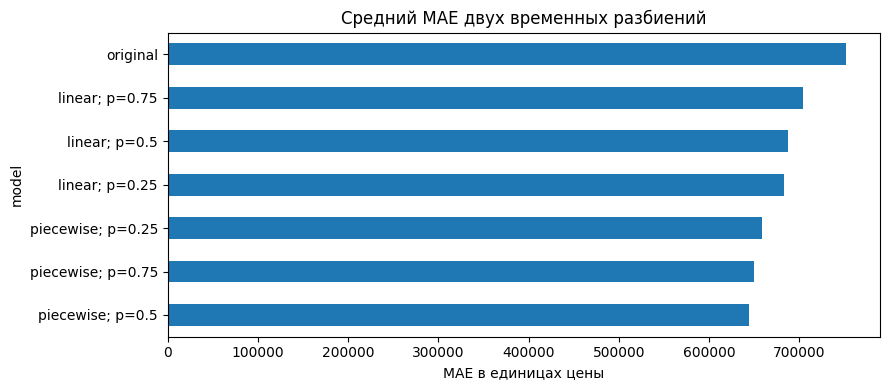

In [5]:
candidates = {
    f'{trend}; p={power}': {'trend': trend, 'weight_power': power}
    for trend in ['piecewise', 'linear']
    for power in [0.25, 0.5, 0.75]
}
rows = []
for fold, start, end in folds:
    fit = dates < start
    valid = (dates >= start) & (dates < end)
    baseline = make_model(**original_config)
    baseline.fit(X.loc[fit], y.loc[fit])
    score = mean_absolute_error(y.loc[valid], baseline.predict(X.loc[valid]))
    rows.append({'fold': fold, 'model': 'original', 'MAE': score})
    print(fold, 'original', round(score))
    for name, config in candidates.items():
        model = ImprovedLinearRegressor(**config)
        model.fit(X.loc[fit], y.loc[fit])
        prediction = model.predict(X.loc[valid])
        assert np.isfinite(prediction).all() and (prediction > 0).all()
        score = mean_absolute_error(y.loc[valid], prediction)
        rows.append({'fold': fold, 'model': name, 'MAE': score})
        print(fold, name, round(score))
cv_results = pd.DataFrame(rows)
table = cv_results.pivot(index='model', columns='fold', values='MAE')
table['mean_MAE'] = table.mean(axis=1)
table = table.sort_values('mean_MAE')
display(table.round(2))
selected_name = table.drop(index='original').index[0]
selected_config = candidates[selected_name].copy()
improvement = 1 - table.loc[selected_name, 'mean_MAE'] / table.loc['original', 'mean_MAE']
print('Выбрано:', selected_config)
print(f'Снижение среднего MAE: {improvement:.1%}')
assert improvement > 0
cv_results.to_csv('improved_cv_results.csv', index=False)
table.mean_MAE.sort_values().plot.barh(figsize=(9, 4), title='Средний MAE двух временных разбиений')
plt.xlabel('MAE в единицах цены')
plt.tight_layout()
plt.show()

## 5. Повторная диагностика на декабре 2012

Выбранные параметры фиксированы. Обе модели обучаются на всех строках до декабря и сравниваются на декабре. Этот месяц уже был просмотрен ранее; результаты описывают повторную проверку и не дают новой независимой оценки. После неё параметры не меняем.

In [6]:
fit = dates < '2012-12-01'
valid = dates >= '2012-12-01'
baseline = make_model(**original_config).fit(X.loc[fit], y.loc[fit])
old_prediction = baseline.predict(X.loc[valid])
model = ImprovedLinearRegressor(**selected_config).fit(X.loc[fit], y.loc[fit])
new_prediction = model.predict(X.loc[valid])
old_mae = mean_absolute_error(y.loc[valid], old_prediction)
new_mae = mean_absolute_error(y.loc[valid], new_prediction)
print(f'Исходная модель, декабрь: {old_mae:,.0f}')
print(f'Новая модель, декабрь: {new_mae:,.0f}')
print(f'Изменение MAE: {(new_mae / old_mae - 1):.1%}')
metrics = {'selected_config': selected_config,
           'cv_mae_original': float(table.loc['original', 'mean_MAE']),
           'cv_mae_improved': float(table.loc[selected_name, 'mean_MAE']),
           'reused_december_mae_original': float(old_mae),
           'reused_december_mae_improved': float(new_mae),
           'note': 'December is reused validation, not a fresh independent holdout.'}
Path('improved_metrics.json').write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding='utf-8')

Исходная модель, декабрь: 791,467
Новая модель, декабрь: 621,325
Изменение MAE: -21.5%


341

## 6. Обучение на всём train и второй файл ответа

Создаём новый файл, не перезаписывая `submission.csv`. Индексы строк не являются признаками. Идентификаторы ответа берём в порядке `sample_submission.csv`.

In [7]:
final_model = ImprovedLinearRegressor(**selected_config)
final_model.fit(X, y)
prediction = final_model.predict(test)
assert np.isfinite(prediction).all() and (prediction > 0).all()
submission = sample[['id']].copy()
submission['price'] = submission.id.map(pd.Series(prediction, index=test.id))
assert submission.shape == (len(test), 2)
assert submission.id.equals(sample.id)
assert submission.id.is_unique and submission.notna().all().all()
submission.to_csv('submission_improved.csv', index=False)
check = pd.read_csv('submission_improved.csv')
assert check.id.equals(sample.id)
assert np.allclose(check.price, submission.price)
print('Сохранён submission_improved.csv:', submission.shape)
display(submission.head())
display(submission.price.describe())
# Проверяем поведение на новой улице и пропусках категорий.
probe = test.iloc[:2].copy()
probe['street_id'] = -999
probe[['build_tech', 'metro_dist', 'g_lift']] = np.nan
assert np.isfinite(final_model.predict(probe)).all()
print('Проверка неизвестной категории и пропусков пройдена.')

Сохранён submission_improved.csv: (100000, 2)


,id,price
0,100000,8.274457e+06
1,100001,4.746310e+06
2,100002,3.908452e+06
3,100003,3.106949e+06
4,100004,6.694286e+06


count    1.000000e+05
mean     5.820648e+06
std      4.589821e+06
min      5.842285e+05
25%      3.146436e+06
50%      4.635134e+06
75%      6.955908e+06
max      9.934687e+07
Name: price, dtype: float64

Проверка неизвестной категории и пропусков пройдена.


## Вывод

Локальный выигрыш измерен относительно исходного решения на одинаковых временных разбиениях. Алгоритм остаётся взвешенной линейной регрессией; улучшены признаки и функция обучения. Итоговые значения MAE и параметры приведены выше и сохранены в `improved_metrics.json`.

Для соревнования предназначен **submission_improved.csv**. Старый **submission.csv** сохранён для сравнения. Качество на public/private станет известно только после загрузки. Экстраполяция временного тренда на 2013 год и неизвестные сочетания категорий остаются ограничениями.